In [8]:
import os
os.environ["OMP_NUM_THREADS"] = "2"

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import silhouette_score

In [10]:
# Generate synthetic interleaved half-circle non-linear data with added noise
X, y = make_moons(n_samples=300, noise=0.08, random_state=42)

print("Dataset Shape:", X.shape)
print("Features count:", X.shape[1])
print("Sample records:\n", np.round(X[:5], 4))

Dataset Shape: (300, 2)
Features count: 2
Sample records:
 [[ 0.6588 -0.356 ]
 [ 1.9863 -0.1335]
 [-0.1116  0.4551]
 [ 0.905   0.2668]
 [ 1.1816 -0.495 ]]


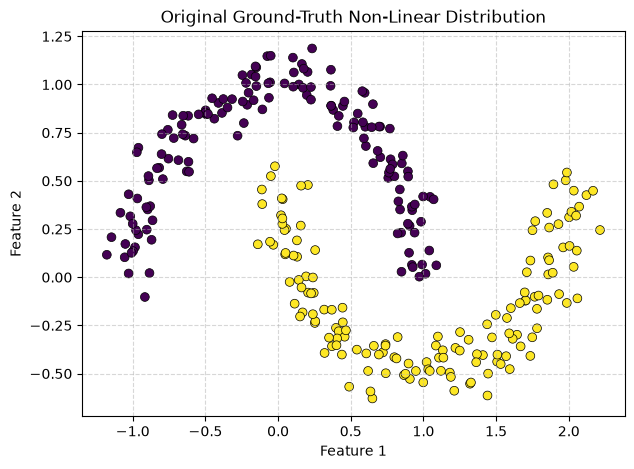

In [11]:
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="viridis", s=40, edgecolors="k", linewidth=0.5)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Original Ground-Truth Non-Linear Distribution")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [12]:
# eps: Neighborhood radius distance; min_samples: Minimum points required to form a core point
eps_val = 0.2
min_samples_val = 5

dbscan = DBSCAN(eps=eps_val, min_samples=min_samples_val)
labels = dbscan.fit_predict(X)

# Calculate clusters (excluding noise label -1) and noise points
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print(f"Optimal Parameters: eps = {eps_val}, min_samples = {min_samples_val}")
print(f"Discovered Clusters : {n_clusters}")
print(f"Identified Outliers/Noise Points: {n_noise}")

Optimal Parameters: eps = 0.2, min_samples = 5
Discovered Clusters : 2
Identified Outliers/Noise Points: 0


In [13]:
# Extract indices of core points identified by DBSCAN
core_samples_mask = np.zeros_like(labels, dtype=bool)
core_samples_mask[dbscan.core_sample_indices_] = True

n_core = np.sum(core_samples_mask)
n_border = len(labels) - n_core - n_noise

point_distribution = pd.DataFrame({
    "Point Category": ["Core Points", "Border Points", "Noise Outliers"],
    "Count": [n_core, n_border, n_noise],
    "Percentage (%)": [
        (n_core / len(labels)) * 100,
        (n_border / len(labels)) * 100,
        (n_noise / len(labels)) * 100
    ]
})

display(point_distribution.round(2))

,Point Category,Count,Percentage (%)
0,Core Points,295,98.33
1,Border Points,5,1.67
2,Noise Outliers,0,0.00


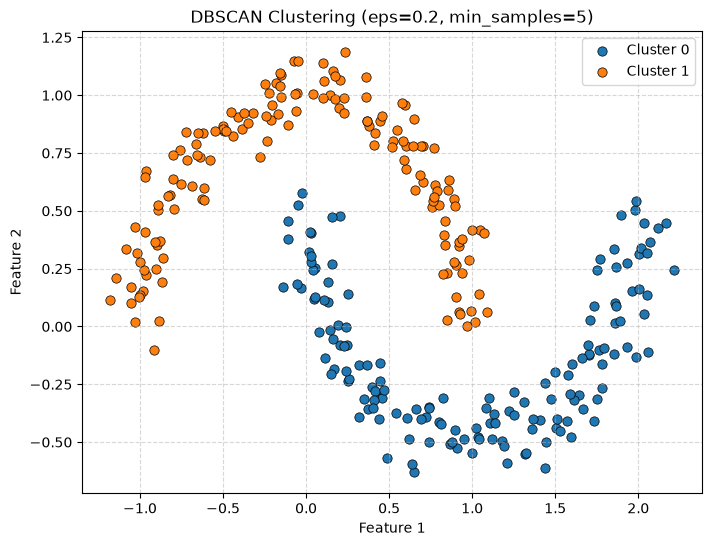

In [14]:
plt.figure(figsize=(8, 6))

unique_labels = set(labels)
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

for idx, label in enumerate(unique_labels):
    if label == -1:
        # Plot noise/outlier points as black crosses
        plt.scatter(
            X[labels == label, 0],
            X[labels == label, 1],
            color="black",
            marker="x",
            s=80,
            linewidth=2,
            label="Noise (-1)"
        )
    else:
        # Plot clustered points
        plt.scatter(
            X[labels == label, 0],
            X[labels == label, 1],
            color=colors[idx % len(colors)],
            s=45,
            edgecolors="k",
            linewidth=0.5,
            label=f"Cluster {label}"
        )

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title(f"DBSCAN Clustering (eps={eps_val}, min_samples={min_samples_val})")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


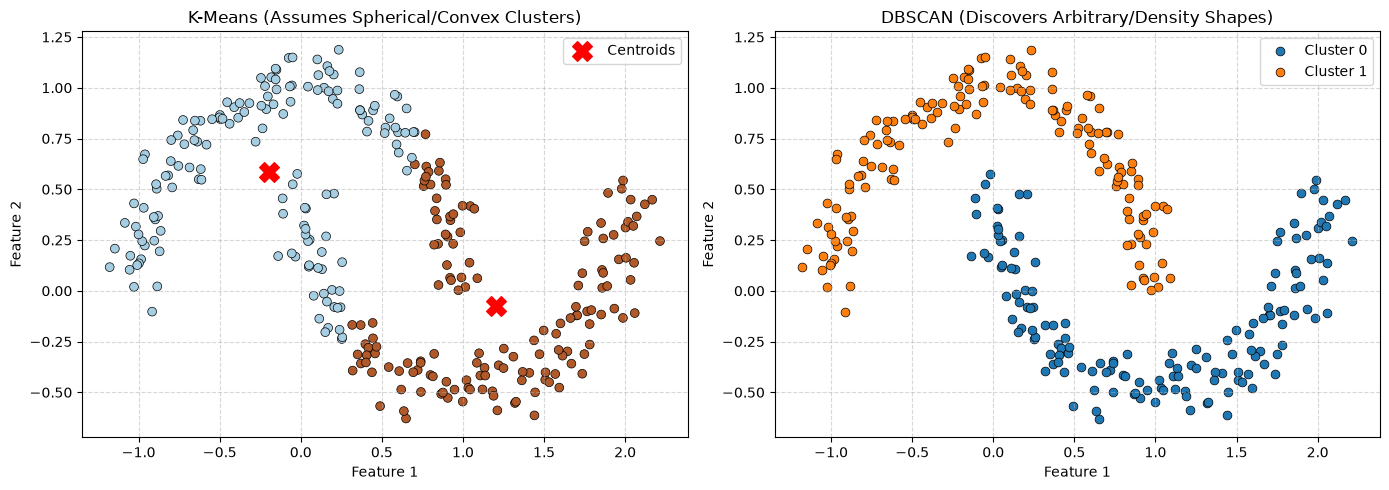

In [15]:
# Run K-Means with K=2 on the same non-linear data
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot K-Means Failure on Non-Linear Data
axes[0].scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap="Paired", s=40, edgecolors="k", linewidth=0.5)
axes[0].scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c="red", marker="X", s=200, label="Centroids")
axes[0].set_title("K-Means (Assumes Spherical/Convex Clusters)")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# Plot DBSCAN Success on Arbitrary Shapes
for idx, label in enumerate(unique_labels):
    if label == -1:
        axes[1].scatter(X[labels == label, 0], X[labels == label, 1], color="black", marker="x", s=70, label="Noise")
    else:
        axes[1].scatter(X[labels == label, 0], X[labels == label, 1], color=colors[idx % len(colors)], s=40, edgecolors="k", linewidth=0.5, label=f"Cluster {label}")

axes[1].set_title("DBSCAN (Discovers Arbitrary/Density Shapes)")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()